# Analysis of trajectories

In [1]:
import json
import os
import pandas as pd
import numpy as np
from tqdm import tqdm
import shutil
from matplotlib import pyplot as plt

os.chdir('/home/fknudsen/calvados-slim')

from src import curation, utils, constants, visualisation
from src.analysis.slim import TwoChain

## Processing

In [2]:
# DeltaG mapping, assuming 25 degree C
def dG(Kd, T:float=298.15):
    if Kd == 0:
        return - np.inf
    return constants.R * T * np.log(Kd)

In [3]:
# Looping over scans
results = []
reuse = False

# Looping over systems
scan_dir = 'sim/scan'
for system in os.listdir(scan_dir):
    system_dir = os.path.join(scan_dir, system)

    # Looping over scans
    for k_dir in tqdm(sorted(os.listdir(system_dir)), desc=f"Analysing '{system}' trajectories"):

        # Determining k-value
        k = float(k_dir.split('=')[-1])
        kd_csv = os.path.join(system_dir, k_dir, 'kd.csv')
        specific_interactions_txt = os.path.join(system_dir, k_dir, 'specific_interactions.txt')

        try:
            # Calculating Kds with blocking SEM estimate
            if not reuse or not os.path.exists(kd_csv):
                if system != 'sh3-prm': # TODO: Remove
                    TwoChain.get_Kd_sem(
                        top_pdb = os.path.join(system_dir, k_dir, 'top.pdb'),
                        traj_dcd = os.path.join(system_dir, k_dir, f'{system}.dcd'),
                        specific_interactions_txt = os.path.join(system_dir, k_dir, 'specific_interactions.txt'),   
                        to_csv = kd_csv
                    )
            Kd, Kd_m1sem, Kd_p1sem = pd.read_csv(kd_csv).values[0]
            
        # Simulation not run yet
        except OSError:
            Kd, Kd_m1sem, Kd_p1sem = (np.NaN, np.NaN, np.NaN)

        # Calculating number of contacts
        with open(specific_interactions_txt, 'r') as file:
            N_C = len(file.readlines())

        # Appending results
        results.append({
            "System": system,
            "k": k,
            "N_C": N_C,
            "Kd": Kd,
            "Kd-1SEM": Kd_m1sem,
            "Kd+1SEM": Kd_p1sem,
            "dG": dG(Kd),
            "dG-1SEM": dG(Kd_m1sem),
            "dG+1SEM": dG(Kd_p1sem),
        })

results = pd.DataFrame(results)


Analysing 'mdm2-p73' trajectories: 100%|██████████| 21/21 [00:01<00:00, 16.21it/s]


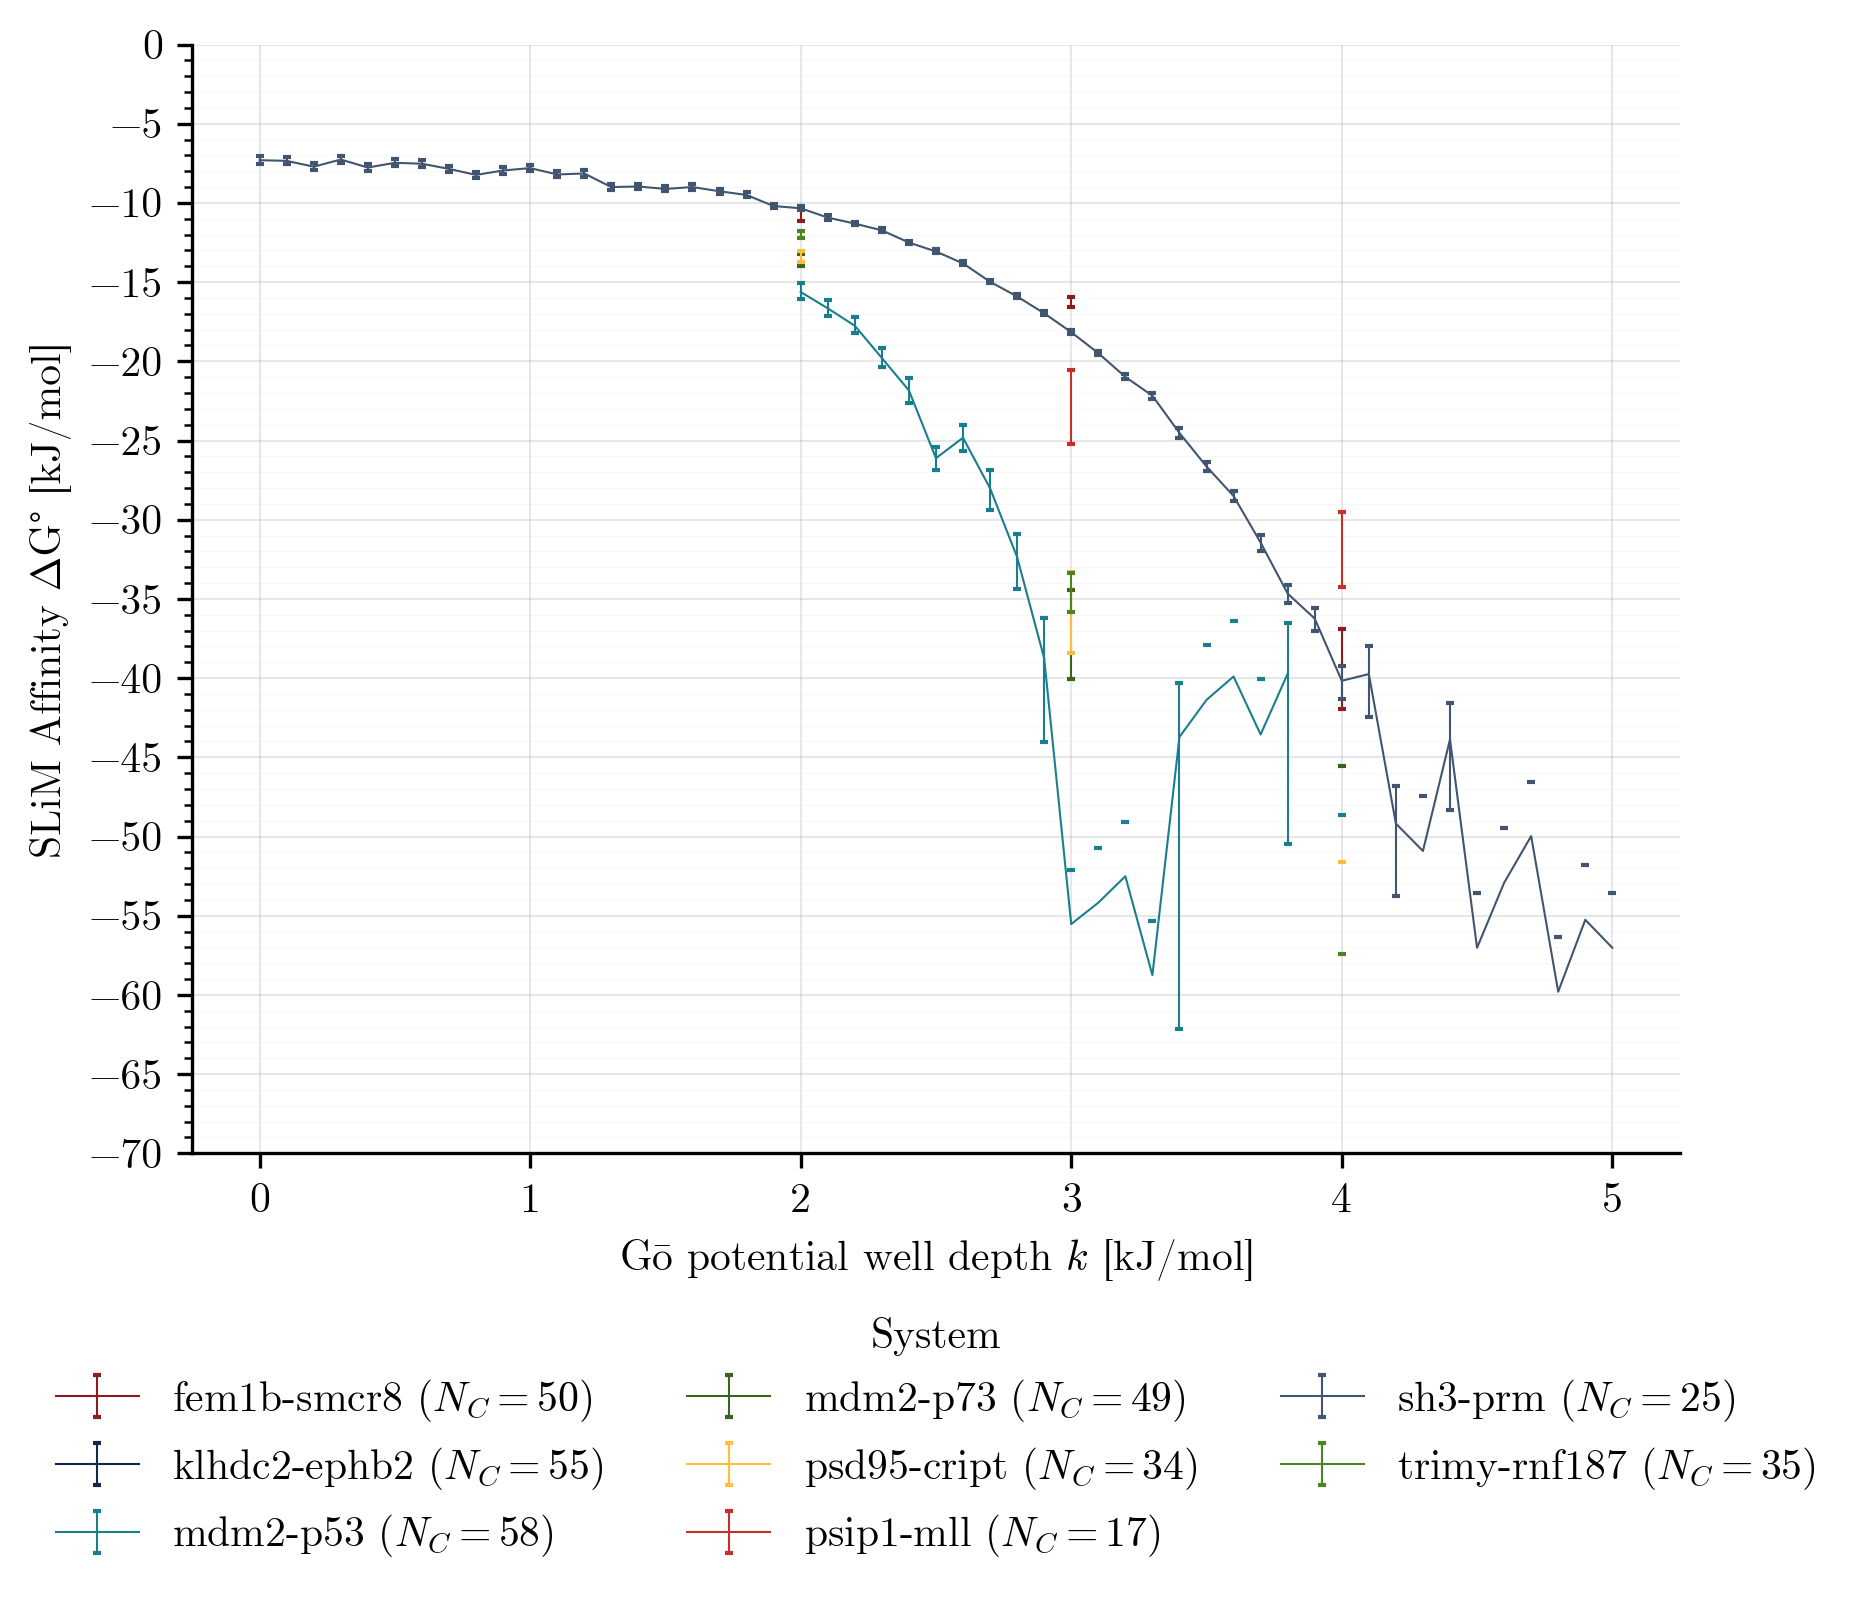

In [4]:
for system, subset in results.groupby('System'):
    dG_err = np.stack([subset['dG'] - subset['dG-1SEM'], subset['dG+1SEM'] - subset['dG']])
    plt.errorbar(
        x = subset['k'], y = subset['dG'], yerr = dG_err,
        ms=1.5, capsize=1, elinewidth=0.5, linewidth=0.5, #fmt = 's', 
        label=f"{system} ($N_C={subset.N_C.mean():.0f}$)"
    )
plt.ylabel('SLiM Affinity ΔG° [kJ/mol]')
plt.xlabel('Gō potential well depth $k$ [kJ/mol]')
ylim = plt.ylim(-70,0)
plt.yticks(np.arange(ylim[0],ylim[1]+.1,5),minor=False)
plt.yticks(np.arange(ylim[0],ylim[1]+.1,1),minor=True)
plt.grid(which='major', alpha=0.3, linewidth=0.5)
plt.grid(which='minor', alpha=0.1, linewidth=0.2)
plt.legend(frameon=False, ncol=3, title="System", loc='lower center', bbox_to_anchor=(0.5,-0.4))


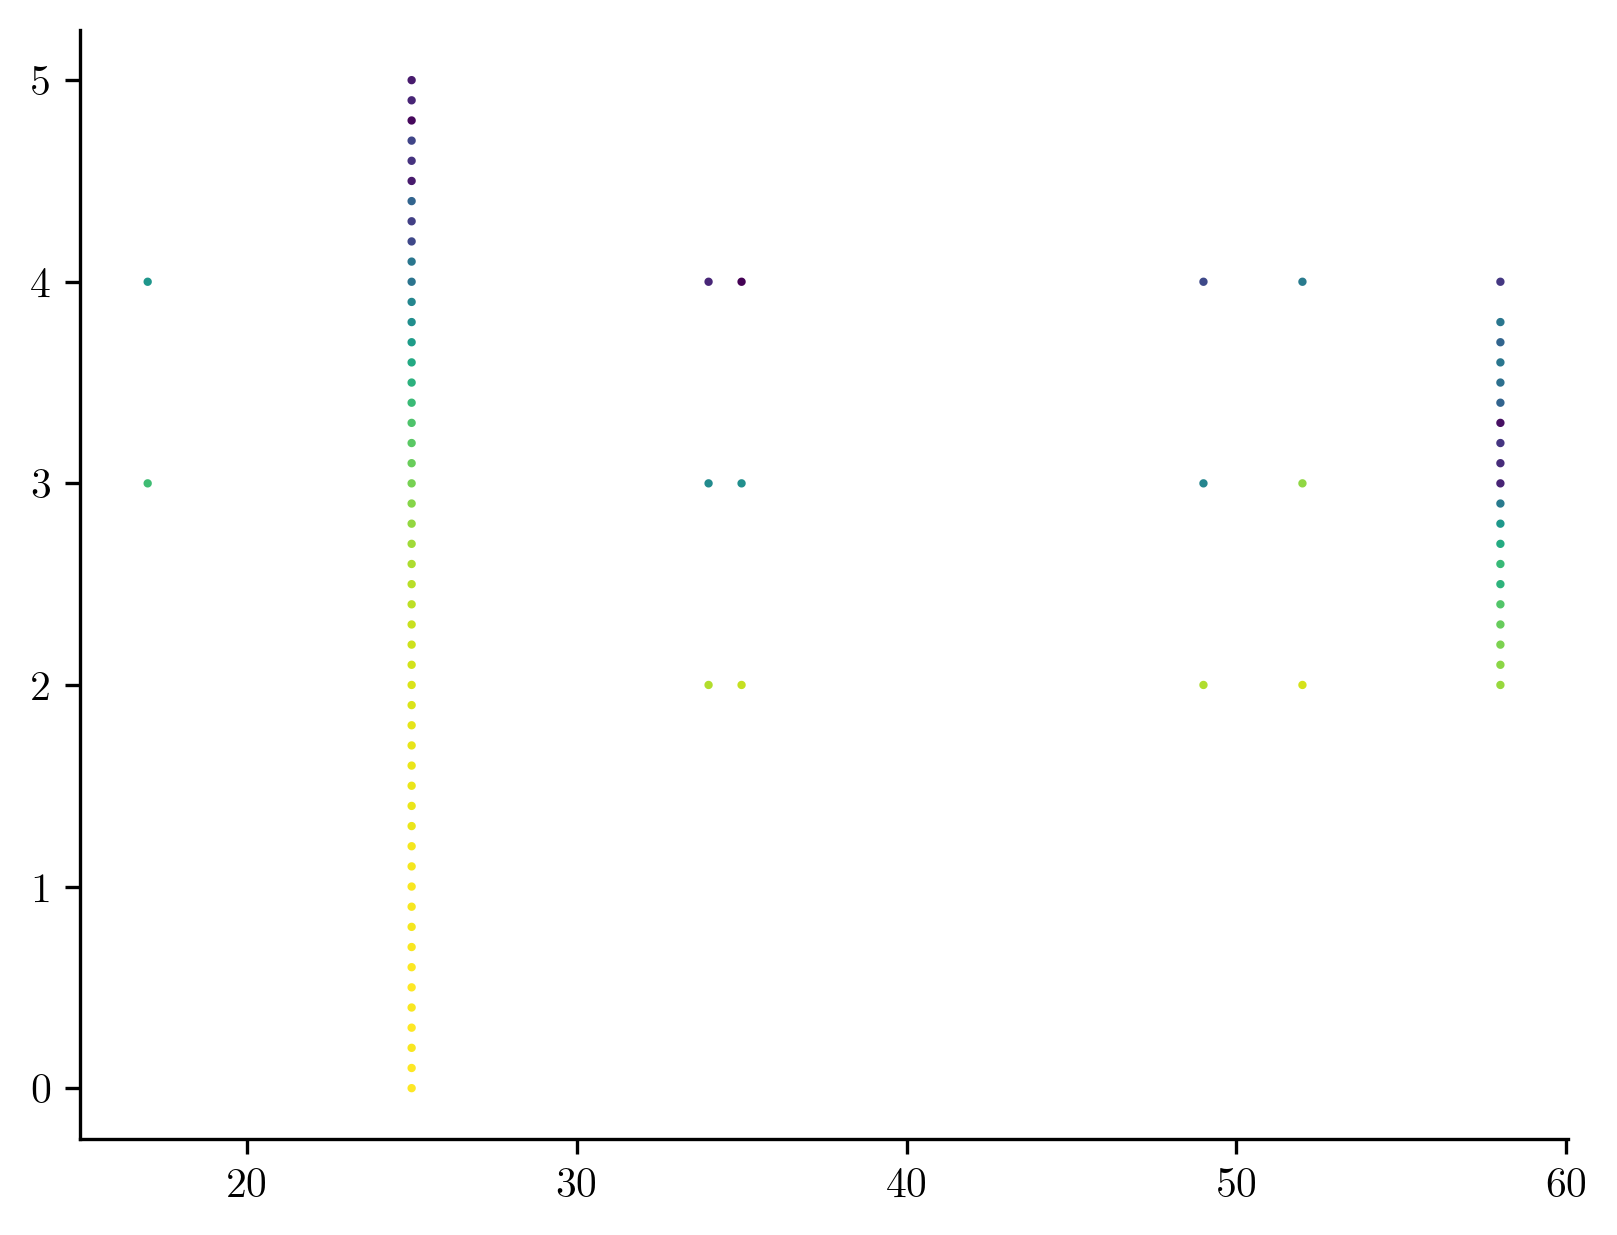

In [5]:
plt.scatter(
    results['N_C'],
    results['k'],
    c=results['dG']
)